# Replication of the main results

*Does the transmission of external shocks depend on the state of business confidence? Evidence for Peru, 2002-2025* (Sánchez and Vassallo).

This notebook re-estimates the two baseline threshold VARs and the joint system with block exogeneity, and reproduces **Figure 3** (GDP response by regime), **Table 2** (pass-through and posterior probability of the asymmetry) and the block-exogeneity rows of **Table 3**. Every other figure and table of the paper is produced by `make all` (about 10 minutes); see `README.md`.

Requirements: `pip install -e .` in this folder (MacroPy 0.3.3 is pulled from its released wheel). Running time: about one minute on a laptop. All specification choices are read from `config.toml`; the figure and table labels are in Spanish, as in the paper.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tvar_shocks import data, load_config, model_specs, variant_config
from tvar_shocks.figures import STYLE, _band, _zero
from tvar_shocks.model import asymmetry, fit, girfs, pass_through

%matplotlib inline

cfg = load_config()
db = data.load()
g = cfg["girf"]
specs = model_specs(cfg)
pd.DataFrame({k: {"variables": ", ".join(s.variables), "shock (pp)": s.shock, "threshold": s.threshold,
                  "lags": s.lags, "sample": f"{s.start[:7]} to {s.end[:7]}"} for k, s in specs.items()}).T

,variables,shock (pp),threshold,lags,sample
chn,"g_ip_chn, g_gdp, g_cpi, int, exp",1.0,50.0,2,2002-04 to 2025-12
ipx,"g_xpi, g_gdp, g_cpi, int, exp",10.0,50.0,2,2002-04 to 2025-12


## 1. Baseline models

One threshold VAR per external shock, with the external variable ordered first. The threshold is fixed at 50 points of the confidence index, the delay is estimated (uniform prior on 1 to 6), the prior hyperparameters are the ones chosen by marginal likelihood in `config.toml`, and the pandemic months are dummied out. MacroPy's sampler is exact: the draws are independent and explosive ones are rejected.

In [2]:
models, resp = {}, {}
for name, spec in specs.items():
    models[name] = fit(spec, db, g["horizon"])
    resp[name] = girfs(models[name], spec, g["n_draws"], g["reps"])
    lml = models[name].log_marginal_likelihood()
    p_low = 1.0 - models[name].regime_probability()
    print(f"{name}: T = {models[name].T}, months in pessimism = {int((p_low > 0.5).sum())}, "
          f"delay (median) = {int(np.median(models[name].draws['delay']))}, "
          f"stable share = {models[name].stable_share:.2f}, log Bayes factor = {lml['log Bayes factor']:.1f}")

chn: T = 259, months in pessimism = 67, delay (median) = 4, stable share = 0.41, log Bayes factor = 2.1


ipx: T = 259, months in pessimism = 67, delay (median) = 4, stable share = 0.52, log Bayes factor = -12.8


### Table 2: pass-through to GDP and posterior probability of the asymmetry

Cumulative response of GDP growth over the cumulative response of the external variable, scaled to the size of the shock, draw by draw: median and 68% interval by regime, and the posterior probability that the pass-through is larger under optimism.

In [3]:
rows = []
for name, spec in specs.items():
    asym = asymmetry(resp[name], spec, g["pass_through"])
    for reg in ("pesimismo", "optimismo"):
        pt = pass_through(resp[name][reg], spec, g["pass_through"])
        for H in g["pass_through"]:
            rows.append({"shock": spec.short, "regime": reg, "horizon": H,
                         "median": round(pt.loc[H, "p50"], 2),
                         "68% interval": f"[{pt.loc[H, 'p16']:.2f}, {pt.loc[H, 'p84']:.2f}]",
                         "Pr(optimism > pessimism)": round(asym.loc[H, "prob_optimism_larger"], 2)})
table2 = pd.DataFrame(rows).set_index(["shock", "regime", "horizon"])
table2

median   68% interval  Pr(optimism > pessimism)
shock regime    horizon                                                 
China pesimismo 12         0.20   [0.12, 0.30]                      0.56
                24         0.30   [0.19, 0.42]                      0.50
                60         0.33   [0.14, 0.54]                      0.56
      optimismo 12         0.22   [0.15, 0.28]                      0.56
                24         0.31   [0.23, 0.39]                      0.50
                60         0.36   [0.20, 0.54]                      0.56
IPX   pesimismo 12         0.32   [0.04, 0.61]                      0.85
                24         0.38   [0.00, 0.82]                      0.92
                60         0.26  [-0.93, 1.17]                      0.87
      optimismo 12         0.59   [0.38, 0.84]                      0.85
                24         0.93   [0.60, 1.32]                      0.92
                60         1.18   [0.41, 2.33]                      0.87

### Figure 3: GDP response by regime

Generalized impulse responses (Koop, Pesaran and Potter, 1996) averaged over the histories of each regime; the regime can switch along the horizon. Median and 68% band.

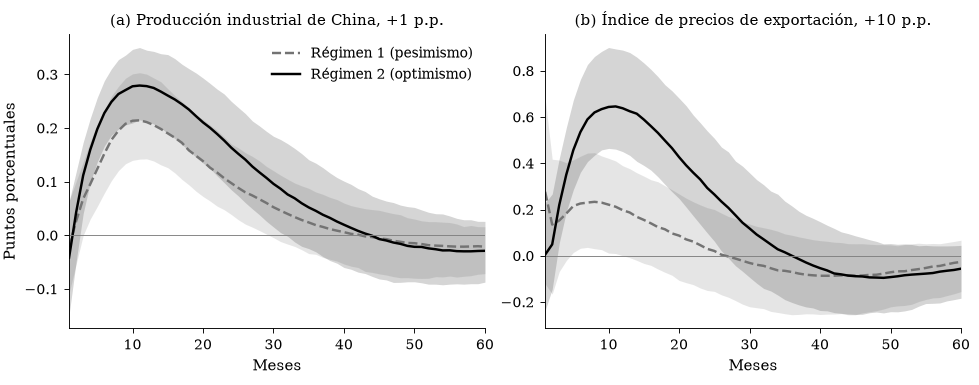

In [4]:
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    for ax, letter, (name, spec) in zip(axes, "ab", specs.items()):
        k = spec.variables.index("g_gdp")
        for reg in ("pesimismo", "optimismo"):
            _band(ax, resp[name][reg][:, :, k], reg)
        _zero(ax); ax.set_xlim(1, g["horizon"]); ax.set_xlabel("Meses")
        ax.set_title(f"({letter}) {spec.label}, +{spec.shock:g} p.p.")
    axes[0].set_ylabel("Puntos porcentuales"); axes[0].legend(loc="upper right")
    fig.tight_layout()
plt.show()

## 2. Joint system with block exogeneity (Table 3, Section 6.5)

China's industrial production and the export price index form a linear external block that does not respond to the Peruvian variables (`ThresholdVAR(b_exo=...)`); the domestic block keeps the threshold structure and responds to the current and lagged external variables. Both shocks are identified in the same estimation.

In [5]:
joint = model_specs(variant_config(cfg, "joint_block"))
n_draws, reps = cfg["robustness"]["grid_n_draws"], cfg["robustness"]["grid_reps"]
model_j = fit(joint["ipx_joint"], db, g["horizon"])          # the same estimation serves both shocks
print(model_j.log_marginal_likelihood().round(2).to_string())
rows, resp_j = [], {}
for name, spec in joint.items():
    resp_j[name] = girfs(model_j, spec, n_draws, reps)
    asym = asymmetry(resp_j[name], spec, g["pass_through"])
    for reg in ("pesimismo", "optimismo"):
        pt = pass_through(resp_j[name][reg], spec, g["pass_through"])
        for H in g["pass_through"][:2]:
            rows.append({"shock": spec.short, "regime": reg, "horizon": H, "median": round(pt.loc[H, "p50"], 2),
                         "68% interval": f"[{pt.loc[H, 'p16']:.2f}, {pt.loc[H, 'p84']:.2f}]",
                         "Pr(optimism > pessimism)": round(asym.loc[H, "prob_optimism_larger"], 2)})
pd.DataFrame(rows).set_index(["shock", "regime", "horizon"])

external block           -1179.99
domestic block, TVAR     -1294.24
domestic block, linear   -1277.50
TVAR                     -2474.23
linear VAR               -2457.49
log Bayes factor           -16.74


median   68% interval  Pr(optimism > pessimism)
shock regime    horizon                                                 
China pesimismo 12         0.19   [0.07, 0.31]                      0.61
                24         0.29   [0.16, 0.43]                      0.58
      optimismo 12         0.22   [0.15, 0.30]                      0.61
                24         0.30   [0.22, 0.38]                      0.58
IPX   pesimismo 12         0.09  [-0.23, 0.38]                      0.66
                24         0.08  [-0.40, 0.50]                      0.79
      optimismo 12         0.22  [-0.03, 0.44]                      0.66
                24         0.33  [-0.05, 0.69]                      0.79

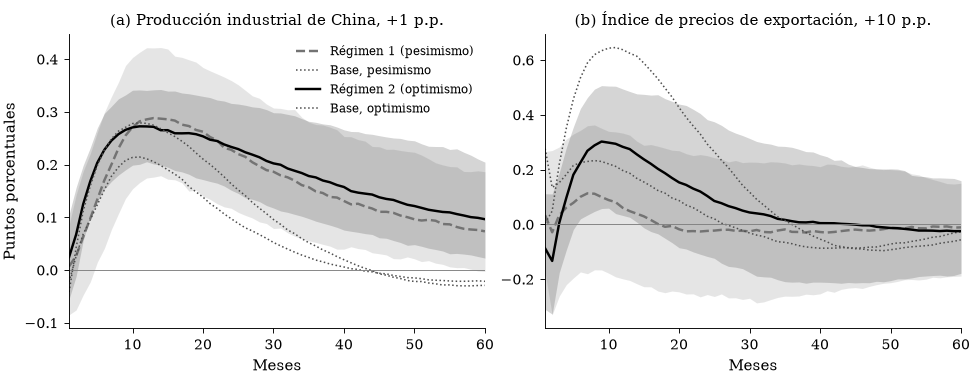

In [6]:
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    for ax, letter, (name, spec) in zip(axes, "ab", joint.items()):
        k = spec.variables.index("g_gdp")
        for reg in ("pesimismo", "optimismo"):
            _band(ax, resp_j[name][reg][:, :, k], reg)
            base = resp[name.split("_")[0]][reg][:, :, specs[name.split("_")[0]].variables.index("g_gdp")]
            ax.plot(np.arange(1, base.shape[1] + 1), np.median(base, axis=0), ls=":", lw=1, color="0.3",
                    label=f"Base, {reg}")
        _zero(ax); ax.set_xlim(1, g["horizon"]); ax.set_xlabel("Meses")
        ax.set_title(f"({letter}) {spec.label}, +{spec.shock:g} p.p.")
    axes[0].set_ylabel("Puntos porcentuales"); axes[0].legend(loc="upper right", fontsize=8)
    fig.tight_layout()
plt.show()

The transmission of external demand is the same in both regimes in every specification; the asymmetry of export prices survives the joint system with a smaller pass-through, since the price shock is now separated from its comovement with global demand. The remaining exercises of the paper (confidence bands, local projections, threshold grid and estimated threshold, alternative priors and external variables, the structural model, fiscal revenue and capital goods imports) are reproduced by `make all`.